In [2]:
!pip install google-generativeai

INFO: pip is looking at multiple versions of google-api-core to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of google-api-core[grpc] to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of googleapis-common-protos to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of grpcio-status to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of grpcio-status to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this ru

In [3]:
# Step 1: Install Gemini SDK if not already
# pip install google-generativeai

import pandas as pd
import numpy as np
import google.generativeai as genai
import matplotlib.pyplot as plt

# --- Step 2: Configure Gemini ---
genai.configure(api_key="AQ.Ab8RN6KsqkouIXDm_tMmA0tBjI-5u8sSkoMzbjeAZketn1G5QA")
model = genai.GenerativeModel("gemini-3.6-flash")

# --- Step 3: Create a synthetic time series dataset ---
# Let's simulate daily temperature data for 100 days
np.random.seed(42)
dates = pd.date_range(start="2024-01-01", periods=100, freq="D")
temps = 20 + np.sin(np.linspace(0, 10, 100)) * 5 + np.random.normal(0, 1, 100)

df = pd.DataFrame({"date": dates, "temperature": temps})

# Plot the dataset
df.plot(x="date", y="temperature", title="Synthetic Daily Temperature", figsize=(10,4))
plt.show()

# --- Step 4: Prepare prompt for Gemini ---
sample_data = df.tail(20).to_dict(orient="records")

prompt = f"""
You are a weather analyst. Based on the following time series of daily temperatures,
predict the temperature trend for the next 7 days.

Dataset sample (last 20 days):
{sample_data}

Return JSON with:
- "forecast": list of objects with "date" and "predicted_temperature"
- "trend": description of whether temperatures are rising, falling, or stable
- "reasoning": brief explanation
"""

# --- Step 5: Run prediction with Gemini ---
response = model.generate_content(prompt)

print("Gemini Weather Forecast Output:")
print(response.text)


ImportError: DLL load failed while importing cygrpc: An Application Control policy has blocked this file.

In [4]:
%pip install -U google-genai requests pandas

   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   --------- ------------------------------ 0.3/1.1 MB ? eta -:--:--
   ----------------------------- ---------- 0.8/1.1 MB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 1.1/1.1 MB 1.9 MB/s  0:00:00
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.8 MB 6.1 MB/s eta 0:00:02
   ------ --------------------------------- 1.6/9.8 MB 4.7 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.8 MB 3.4 MB/s eta 0:00:03
   ---------- ----------------------------- 2.6/9.8 MB 3.4 MB/s eta 0:00:03
   -------------- ------------------------- 3.7/9.8 MB 3.5 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.8 MB 3.8 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires pandas<3,>=1.4.0, but you have pandas 3.0.5 which is incompatible.


In [1]:
import requests

API_KEY = "AQ.Ab8RN6KsqkouIXDm_tMmA0tBjI-5u8sSkoMzbjeAZketn1G5QA"
MODEL = "gemini-3.6-flash"

url = f"https://generativelanguage.googleapis.com/v1beta/models/{MODEL}:generateContent?key={API_KEY}"

headers = {"Content-Type": "application/json"}

prompt = {
  "contents": [
    {"parts":[{"text":"Predict tomorrow's weather based on this dataset: [20,21,22,23,24]"}]}
  ]
}

response = requests.post(url, headers=headers, json=prompt)

print(response.json())


{'candidates': [{'content': {'parts': [{'text': "Based purely on the linear trend in your dataset (where each value increases by 1), the predicted value for tomorrow is **25**.\n\nHere is how that translates to tomorrow's weather depending on what your dataset represents:\n\n### 1. If this represents Temperature in Celsius (°C)\n* **Forecast:** **25°C** (77°F)\n* **Conditions:** Warm, pleasant, and sunny. The warming trend continues, making tomorrow slightly warmer than today. \n\n### 2. If this represents Temperature in Fahrenheit (°F)\n* **Forecast:** **25°F** (-4°C)\n* **Conditions:** Below freezing, very cold. You will need a heavy winter coat, and there may be frost or icy conditions.\n\n### 3. If this represents Precipitation Chance (%)\n* **Forecast:** **25% chance of rain**\n* **Conditions:** Mostly dry/partly cloudy, but with a slight, gradually increasing risk of light showers.\n\n---\n\n### ⚠️ Meteorological Note\nIn real-world meteorology, weather rarely follows a strict li

In [2]:
result = response.json()
forecast_text = result["candidates"][0]["content"]["parts"][0]["text"]
print(forecast_text)


Based purely on the linear trend in your dataset (where each value increases by 1), the predicted value for tomorrow is **25**.

Here is how that translates to tomorrow's weather depending on what your dataset represents:

### 1. If this represents Temperature in Celsius (°C)
* **Forecast:** **25°C** (77°F)
* **Conditions:** Warm, pleasant, and sunny. The warming trend continues, making tomorrow slightly warmer than today. 

### 2. If this represents Temperature in Fahrenheit (°F)
* **Forecast:** **25°F** (-4°C)
* **Conditions:** Below freezing, very cold. You will need a heavy winter coat, and there may be frost or icy conditions.

### 3. If this represents Precipitation Chance (%)
* **Forecast:** **25% chance of rain**
* **Conditions:** Mostly dry/partly cloudy, but with a slight, gradually increasing risk of light showers.

---

### ⚠️ Meteorological Note
In real-world meteorology, weather rarely follows a strict linear pattern ($+1$ every day) indefinitely. A true weather forecast 

Raw Gemini Output:
 {
  "forecast": [
    {
      "date": "2024-05-20",
      "predicted_temperature": 25
    },
    {
      "date": "2024-05-21",
      "predicted_temperature": 26
    },
    {
      "date": "2024-05-22",
      "predicted_temperature": 27
    },
    {
      "date": "2024-05-23",
      "predicted_temperature": 28
    },
    {
      "date": "2024-05-24",
      "predicted_temperature": 29
    },
    {
      "date": "2024-05-25",
      "predicted_temperature": 30
    },
    {
      "date": "2024-05-26",
      "predicted_temperature": 31
    }
  ]
}

Parsed Forecast DataFrame:
          date  predicted_temperature
0  2024-05-20                     25
1  2024-05-21                     26
2  2024-05-22                     27
3  2024-05-23                     28
4  2024-05-24                     29
5  2024-05-25                     30
6  2024-05-26                     31


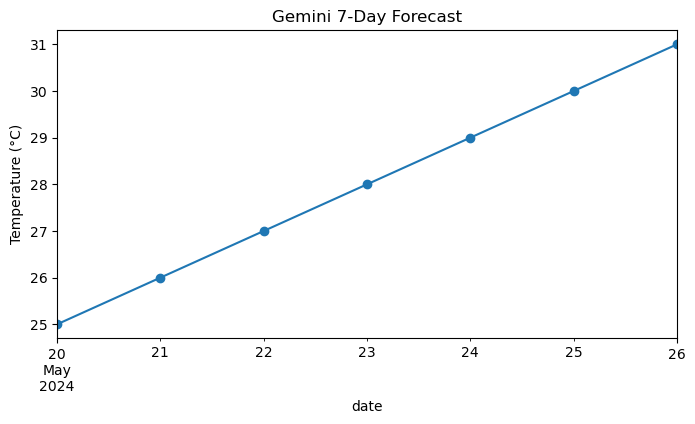

In [5]:
import pandas as pd
import requests
import json
import matplotlib.pyplot as plt

# --- Step 1: Setup ---
API_KEY = "AQ.Ab8RN6KsqkouIXDm_tMmA0tBjI-5u8sSkoMzbjeAZketn1G5QA"   # <-- replace with your actual key
MODEL = "gemini-3.6-flash"

url = f"https://generativelanguage.googleapis.com/v1beta/models/{MODEL}:generateContent?key={API_KEY}"
headers = {"Content-Type": "application/json"}

# --- Step 2: Prompt Gemini ---
prompt = {
  "contents": [
    {"parts":[{"text": """
Return a 7-day weather forecast in strict JSON format:
{
  "forecast": [
    {"date": "YYYY-MM-DD", "predicted_temperature": number}
  ]
}
Dataset: [20,21,22,23,24]
"""}]}
  ]
}

response = requests.post(url, headers=headers, json=prompt)
result = response.json()

# --- Step 3: Extract Gemini output ---
if "candidates" in result:
    forecast_text = result["candidates"][0]["content"]["parts"][0]["text"]
    print("Raw Gemini Output:\n", forecast_text)

    # --- Step 4: Parse JSON safely ---
    try:
        forecast_data = json.loads(forecast_text)
    except json.JSONDecodeError:
        print("Gemini output was not valid JSON.")
        forecast_data = {}

    # --- Step 5: Load into DataFrame ---
    if isinstance(forecast_data, dict) and "forecast" in forecast_data:
        df_forecast = pd.DataFrame(forecast_data["forecast"])
        print("\nParsed Forecast DataFrame:\n", df_forecast)

        # --- Step 6: Plot forecast ---
        df_forecast["date"] = pd.to_datetime(df_forecast["date"])
        df_forecast.set_index("date", inplace=True)
        df_forecast["predicted_temperature"].plot(marker="o", figsize=(8,4), title="Gemini 7-Day Forecast")
        plt.ylabel("Temperature (°C)")
        plt.show()
    else:
        print("No 'forecast' key found in Gemini output.")
else:
    print("Error from Gemini API:\n", result)


In [6]:
pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
    --------------------------------------- 0.3/12.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.1 MB 1.3 MB/s eta 0:00:09
   ---- ----------------------------------- 1.3/12.1 MB 2.4 MB/s eta 0:00:05
   ------ --------------------------------- 2.1/12.1 MB 2.9 MB/s eta 0:00:04
   --------- ------------------------------ 2.9/12.1 MB 3.2 MB/s eta 0:00:03
   ------------ --------------------------- 3.9/12.1 MB 3.6 MB/s eta 0:00:03
   ----------------- ---------------------- 5.2/12.1 MB 4.0 MB/s eta 0:00:02
   --------------------- ------------------ 6.6/12.1 MB 4.3 MB/s eta 0:00:02
   ------------------------- -------------- 7.9/12.1 MB 4.6 MB/s eta 0:00:01
   ------------------------------ --------- 9.2/12.1 MB 4.8 MB/s eta 0:00:01
   ------------------------

In [1]:
#Time series model - Prophet
# Step 1: Install Prophet if not already

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet

# --- Step 2: Create synthetic dataset ---
# Let's simulate daily temperature data for 100 days
np.random.seed(42)
dates = pd.date_range(start="2024-01-01", periods=100, freq="D")
temps = 20 + np.sin(np.linspace(0, 10, 100)) * 5 + np.random.normal(0, 1, 100)

df = pd.DataFrame({"ds": dates, "y": temps})  # Prophet requires columns 'ds' (date) and 'y' (value)

# --- Step 3: Initialize and fit Prophet model ---
model = Prophet()
model.fit(df)

# --- Step 4: Make future dataframe ---
future = model.make_future_dataframe(periods=7)  # forecast 7 days ahead

# --- Step 5: Predict ---
forecast = model.predict(future)

# --- Step 6: Plot forecast ---
fig1 = model.plot(forecast)
plt.title("Prophet Forecast: Daily Temperature")
plt.show()

# Optional: Plot forecast components (trend, seasonality)
fig2 = model.plot_components(forecast)
plt.show()


21:26:31 - cmdstanpy - INFO - Chain [1] start processing
21:27:06 - cmdstanpy - INFO - Chain [1] done processing
21:27:06 - cmdstanpy - ERROR - Chain [1] error: code '3236495362' 
Optimization terminated abnormally. Falling back to Newton.
21:27:06 - cmdstanpy - INFO - Chain [1] start processing
21:27:09 - cmdstanpy - INFO - Chain [1] done processing
21:27:09 - cmdstanpy - ERROR - Chain [1] error: code '3236495362' 


RuntimeError: Error during optimization! Command 'C:\Users\Lamees\anaconda3\Lib\site-packages\prophet\stan_model\prophet_model.bin random seed=47030 data file=C:\Users\Lamees\AppData\Local\Temp\tmpa5u2vdoy\vopb50ai.json init=C:\Users\Lamees\AppData\Local\Temp\tmpa5u2vdoy\zf0cdl1y.json output file=C:\Users\Lamees\AppData\Local\Temp\tmpa5u2vdoy\prophet_modelcjsiwkbi\prophet_model-20260901212706.csv method=optimize algorithm=newton iter=10000' failed: 